# 03 · Modelo predictivo simple del IRCA municipal

**Objetivo:** pronosticar el IRCA 2026 de cada municipio con datos 2025, usando solo información de años anteriores.

**Decisión:** se compara un pronóstico ingenuo, la media histórica, una regresión lineal simple (IRCA del año anterior + media móvil de 3 años), una regresión completa y un Random Forest. El modelo final es la regresión simple por parsimonia y estabilidad: su MAE es prácticamente igual al de la regresión completa y produce escenarios menos agresivos.

**Corte temporal:** entrenamiento ≤ 2021 (463 observaciones), prueba 2022–2025 (127). No se usa información del futuro para entrenar.

In [1]:
import os
import sys
from pathlib import Path

BASE = Path.cwd()
if BASE.name == "notebooks":
    BASE = BASE.parent
    os.chdir(BASE)
sys.path.insert(0, str(BASE))

import pandas as pd

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 170)
print("Directorio de trabajo:", Path.cwd())

Directorio de trabajo: C:\Users\chris\Desktop\electiva-profesional-ii-trabajo-final


## 1. Panel anual completo

Se construye una grilla 2007–2026 por municipio. Así los rezagos son de año calendario y no de fila: si un municipio no reportó un año, el rezago queda nulo en lugar de tomar un dato antiguo como si fuera del año anterior.

In [2]:
from src.model import FEATURES_COMPLETO, FEATURES_SIMPLE, preparar_panel

cauca = pd.read_csv("data/clean/irca_cauca_municipal.csv", encoding="utf-8-sig")
cauca["anio"] = cauca["anio"].astype(int)
panel = preparar_panel(cauca)

print("Panel:", panel.shape)
print("Variables simples:", FEATURES_SIMPLE)
print("Variables completas:", FEATURES_COMPLETO)
panel[panel["municipio"] == "Timbiquí"][
    ["anio", "irca", "irca_lag1", "irca_lag2", "irca_roll3", "tendencia_3"]
].tail(10)

Panel: (840, 25)
Variables simples: ['irca_lag1', 'irca_roll3']
Variables completas: ['irca_lag1', 'irca_lag2', 'irca_roll3', 'irca_urbano_lag1', 'anios_en_riesgo_prev', 'irca_mean_prev', 'tendencia_3', 'reporta_rural_prev']


,anio,irca,irca_lag1,irca_lag2,irca_roll3,tendencia_3
750,2017,94.5,96.6,96.1,95.233333,3.6
751,2018,94.6,94.5,96.6,95.733333,-1.6
752,2019,21.5,94.6,94.5,95.233333,-2.0
753,2020,10.8,21.5,94.6,70.200000,-73.0
754,2021,12.9,10.8,21.5,42.300000,-83.8
755,2022,NaN,12.9,10.8,15.066667,-8.6
756,2023,NaN,NaN,12.9,11.850000,NaN
757,2024,18.6,NaN,NaN,NaN,NaN
758,2025,37.0,18.6,NaN,NaN,NaN
759,2026,NaN,37.0,18.6,27.800000,NaN


## 2. Conjunto de entrenamiento y prueba

In [3]:
datos = panel.dropna(subset=["irca"] + FEATURES_COMPLETO).copy()
train = datos[datos["anio"] <= 2021]
test = datos[datos["anio"] >= 2022]

print("Observaciones completas:", len(datos))
print("Entrenamiento:", len(train), "| años:", int(train["anio"].min()), "-", int(train["anio"].max()))
print("Prueba:", len(test), "| años:", int(test["anio"].min()), "-", int(test["anio"].max()))

Observaciones completas: 590
Entrenamiento: 463 | años: 2010 - 2021
Prueba: 127 | años: 2022 - 2025


## 3. Modelo simple y métricas de prueba

In [4]:
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from src.model import calcular_metricas

modelo_simple = Pipeline(
    [("escalador", StandardScaler()), ("modelo", LinearRegression())]
)
modelo_simple.fit(train[FEATURES_SIMPLE], train["irca"])
pred_simple = modelo_simple.predict(test[FEATURES_SIMPLE])

print("Regresión lineal simple:")
print(calcular_metricas(test["irca"], pred_simple))

Regresión lineal simple:


{'n': 127, 'mae': 5.26, 'rmse': 8.57, 'r2': -0.06, 'mape': 215.9}


## 4. Comparación con los modelos alternativos

In [5]:
from sklearn.ensemble import RandomForestRegressor

modelo_completo = Pipeline(
    [("escalador", StandardScaler()), ("modelo", LinearRegression())]
)
modelo_completo.fit(train[FEATURES_COMPLETO], train["irca"])
pred_completo = modelo_completo.predict(test[FEATURES_COMPLETO])

modelo_rf = RandomForestRegressor(
    n_estimators=500,
    max_depth=4,
    min_samples_leaf=3,
    random_state=42,
    n_jobs=-1,
)
modelo_rf.fit(train[FEATURES_COMPLETO], train["irca"])
pred_rf = modelo_rf.predict(test[FEATURES_COMPLETO])

comparacion = pd.DataFrame(
    [
        {"modelo": "Naive (último valor)", **calcular_metricas(test["irca"], test["irca_lag1"])},
        {"modelo": "Media histórica", **calcular_metricas(test["irca"], test["irca_mean_prev"])},
        {"modelo": "Regresión simple", **calcular_metricas(test["irca"], pred_simple)},
        {"modelo": "Regresión completa", **calcular_metricas(test["irca"], pred_completo)},
        {"modelo": "Random Forest", **calcular_metricas(test["irca"], pred_rf)},
    ]
)
comparacion

,modelo,n,mae,rmse,r2,mape
0,Naive (último valor),127,5.63,10.13,-0.482,212.0
1,Media histórica,127,14.26,20.23,-4.912,660.1
2,Regresión simple,127,5.26,8.57,-0.060,215.9
3,Regresión completa,127,5.25,8.29,0.007,202.4
4,Random Forest,127,5.88,8.07,0.060,305.3


**Lectura:** el MAE de la regresión simple (5,26) mejora en 0,37 puntos al naive (5,63). La regresión completa baja apenas 0,01 puntos más, pero usa 8 variables. El R² de prueba es negativo o casi nulo: el modelo no explica bien la varianza. El R² de entrenamiento es 0,73, lo que evidencia sobreajuste y cambios estructurales entre periodos.

## 5. Coeficientes del modelo final

El modelo de prueba se entrena solo con ≤2021. Para el pronóstico 2026 se reentrena con todos los datos completos (práctica estándar de pronóstico). Los coeficientes que se reportan son los del modelo reentrenado.

In [6]:
modelo_final = Pipeline(
    [("escalador", StandardScaler()), ("modelo", LinearRegression())]
)
modelo_final.fit(datos[FEATURES_SIMPLE], datos["irca"])

coeficientes = pd.DataFrame(
    {
        "variable": FEATURES_SIMPLE,
        "coeficiente_estandarizado": modelo_final.named_steps["modelo"].coef_.round(4),
    }
)
coeficientes

,variable,coeficiente_estandarizado
0,irca_lag1,12.4180
1,irca_roll3,6.7312


## 6. Pronóstico 2026

El escenario usa el IRCA 2025 y la media móvil 2023–2025. La banda de error usa el MAE de prueba (±5,26 puntos); **no es un intervalo de confianza**.

In [7]:
from src.model import categoria, construir_futuro

futuro = construir_futuro(cauca)
futuro["irca_2026_predicho"] = modelo_final.predict(futuro[FEATURES_SIMPLE]).clip(0, 100)
futuro["categoria_predicha"] = futuro["irca_2026_predicho"].map(categoria)
futuro["intervalo_inferior"] = (futuro["irca_2026_predicho"] - 5.26).clip(0, 100)
futuro["intervalo_superior"] = (futuro["irca_2026_predicho"] + 5.26).clip(0, 100)

futuro[
    [
        "municipio",
        "irca_lag1",
        "irca_roll3",
        "irca_2026_predicho",
        "categoria_predicha",
        "intervalo_inferior",
        "intervalo_superior",
    ]
].sort_values("irca_2026_predicho", ascending=False).head(10)

,municipio,irca_lag1,irca_roll3,irca_2026_predicho,categoria_predicha,intervalo_inferior,intervalo_superior
759,Timbiquí,37.0,27.800000,28.682915,Riesgo medio,23.422915,33.942915
139,Caldono,36.6,20.066667,26.225078,Riesgo medio,20.965078,31.485078
259,Guapi,32.0,26.966667,25.785337,Riesgo medio,20.525337,31.045337
839,Villa Rica,19.1,11.333333,14.394674,Riesgo medio,9.134674,19.654674
299,Jambaló,12.5,12.500000,11.228003,Riesgo bajo,5.968003,16.488003
479,Piamonte,11.4,12.666667,10.692159,Riesgo bajo,5.432159,15.952159
439,Padilla,12.6,10.433333,10.681054,Riesgo bajo,5.421054,15.941054
379,Mercaderes,12.4,9.866667,10.410297,Riesgo bajo,5.150297,15.670297
739,Suárez,11.5,6.466667,8.945089,Riesgo bajo,3.685089,14.205089
119,Cajibío,11.1,4.033333,8.026117,Riesgo bajo,2.766117,13.286117


In [8]:
print("Categorías pronosticadas 2026:")
print(futuro["categoria_predicha"].value_counts().to_string())

Categorías pronosticadas 2026:
categoria_predicha
Sin riesgo      20
Riesgo bajo     14
Riesgo medio     4


## 7. Figura oficial del modelo

Se ejecuta el flujo oficial para regenerar la figura y las tablas del modelo.

Preparando panel...


  Filas con variables completas: 590
  Entrenamiento (<=2021): 463 | Prueba (>=2022): 127



Métricas de prueba:
                   modelo   n   mae  rmse     r2  mape
     Naive (último valor) 127  5.63 10.13 -0.482 212.0
Media histórica municipal 127 14.26 20.23 -4.912 660.1
  Regresión lineal simple 127  5.26  8.57 -0.060 215.9
Regresión lineal completa 127  5.25  8.29  0.007 202.4
            Random Forest 127  5.88  8.07  0.060 305.3

Modelo final: Regresión lineal simple (MAE=5.26)
Criterio: parsimonia y estabilidad; el modelo completo mejora el MAE solo marginalmente.

Coeficientes del modelo final:
  variable              etiqueta  coeficiente_estandarizado
 irca_lag1 IRCA del año anterior                    12.4180
irca_roll3 Media móvil de 3 años                     6.7312

Construyendo pronóstico 2026...



Pronóstico 2026 (primeros 10):
 municipio  irca_2025  irca_2026_predicho categoria_predicha  cambio_esperado
  Timbiquí       37.0               28.68       Riesgo medio            -8.32
   Caldono       36.6               26.23       Riesgo medio           -10.37
     Guapi       32.0               25.79       Riesgo medio            -6.21
Villa Rica       19.1               14.39       Riesgo medio            -4.71
   Jambaló       12.5               11.23        Riesgo bajo            -1.27
  Piamonte       11.4               10.69        Riesgo bajo            -0.71
   Padilla       12.6               10.68        Riesgo bajo            -1.92
Mercaderes       12.4               10.41        Riesgo bajo            -1.99
    Suárez       11.5                8.95        Riesgo bajo            -2.55
   Cajibío       11.1                8.03        Riesgo bajo            -3.07

Archivos generados: metricas_modelo.csv, predicciones_2026.csv, fig_07_modelo.png


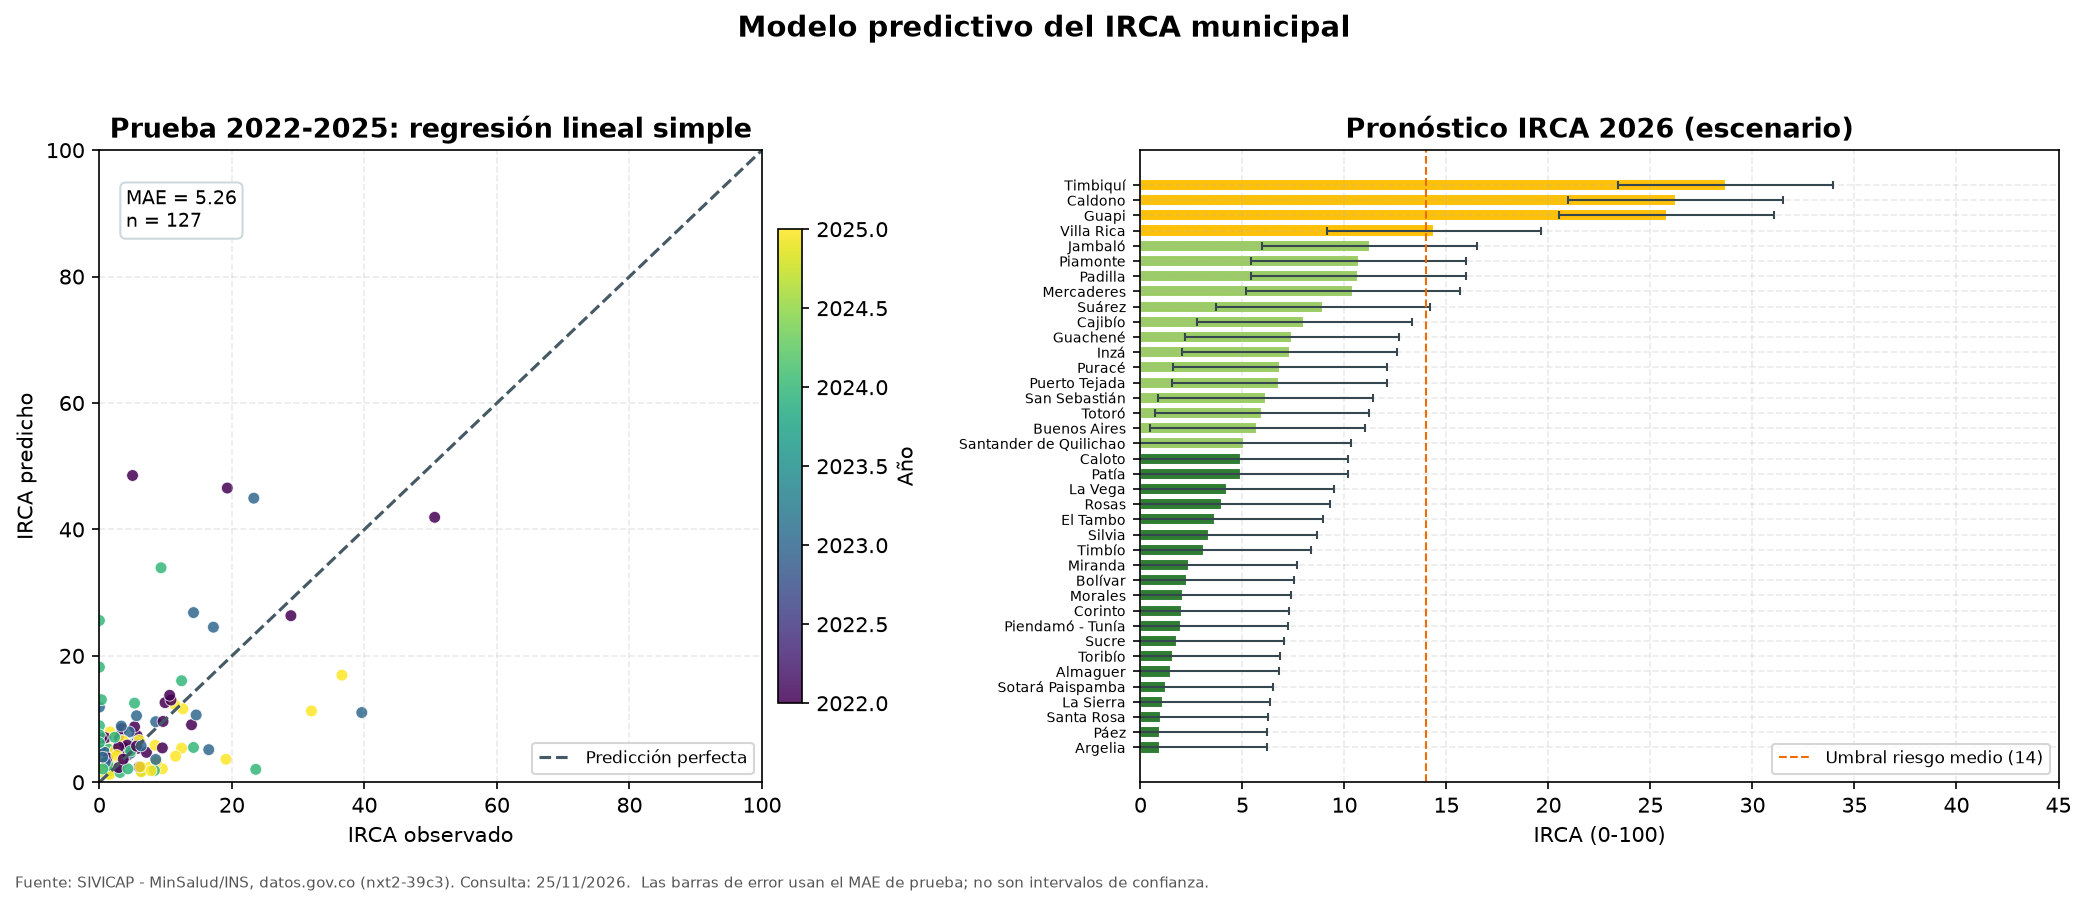

In [9]:
from IPython.display import Image, display
from src.model import main

main()
display(Image(filename="figures/fig_07_modelo.png", width=1000))

## 8. Conclusiones del modelo

- **MAE de prueba:** 5,26 puntos; naive: 5,63. La mejora es modesta.
- **R² de prueba:** -0,06; R² de entrenamiento: 0,73. El modelo no generaliza bien y suaviza los extremos.
- **Pronóstico 2026:** 4 municipios en riesgo medio (Timbiquí 28,7; Caldono 26,2; Guapi 25,8; Villa Rica 14,4), 14 en riesgo bajo y 20 sin riesgo. No se pronostica riesgo alto, pero Timbiquí y Caldono quedan cerca del umbral de 35.
- **Uso responsable:** es una herramienta de tamizaje y exploración, no una predicción oficial ni una relación causal. La priorización debe validarse con datos de campo, infraestructura, clima e inversión.

> **Nota metodológica:** la banda ±MAE no es un intervalo de confianza. Para intervalos formales se necesitaría un bootstrap o un modelo probabilístico, que excede el alcance de este trabajo.